# ¿Qué película de terror encaja en mi noche de Halloween?
**Categoría: EDA (análisis exploratorio de datos).** Consulta: 26 de octubre de 2026. Votos: MovieLens 32M, hasta el 12 de octubre de 2023.

Me pregunto cuánto cambia una recomendación cuando considero el tiempo disponible y el tipo de experiencia, en lugar de ordenar todo por nota. No entreno un modelo ni predigo el gusto o el miedo de ninguna persona. Exploro 120 títulos seleccionados editorialmente entre 1922 y 2022, incluido el mediometraje televisivo *La cabina*.

## Ruta de lectura y glosario
Primero documento y preparo los datos. Después comparo épocas, tiempos, familias de terror y valoraciones. Termino con comprobaciones de sensibilidad y reglas del recomendador.
- **Media:** sumo las estrellas y las divido por el número de votos de una película.
- **Mediana:** ordeno las películas y tomo el valor central. Cada título pesa igual.
- **Votos:** valoraciones presentes en esta muestra de MovieLens; no son espectadores, entradas vendidas ni popularidad mundial.
- **Familia:** etiqueta editorial, compatible con otras. Una película puede ser de monstruos y ciencia ficción.
- **Intensidad:** orientación editorial, nunca una medición del miedo ni una clasificación por edades.

## 1. Fuentes y límites de la selección
Uso [MovieLens 32M, de GroupLens](https://grouplens.org/datasets/movielens/32m/), una versión estable con 32.000.204 votos de 200.948 usuarios. Selecciono 120 títulos por variedad de épocas, procedencias y tipos de terror, antes de calcular sus notas. No construyo una muestra aleatoria ni un censo del género. Incluyo fantasía, comedia y suspense próximos al terror. No incluyo estrenos posteriores a 2022 y no interpreto las notas como actuales.

Cito a F. Maxwell Harper y Joseph A. Konstan (2015), *The MovieLens Datasets: History and Context*, [doi:10.1145/2827872](https://doi.org/10.1145/2827872). Conservo su licencia en `LICENCIA_MOVIELENS.txt`; esta transformación mantiene esas condiciones y no implica respaldo de GroupLens.

Cruzo por identificador IMDb con [Wikidata](https://www.wikidata.org/) para obtener países y géneros. Sus datos estructurados son CC0. Contrasto las duraciones con la ficha inglesa de Wikipedia, cuyo enlace conservo para cada título. Uso el mayor valor de la **ficha** cuando indica varios; no afirmo haber catalogado todos los montajes. La duración de la copia que se vaya a ver puede variar.

Escribo sinopsis propias y asigno etiquetas editoriales consultando los argumentos enlazados. No son un resultado de MovieLens. Mantengo los títulos habituales en España; no sustituyo automáticamente el título por la etiqueta de Wikidata. Conservo sin alterar el año del catálogo y documento la discrepancia de *El ejército de las tinieblas*: 1992 en mi selección por su estreno en festival, 1993 en MovieLens. Sustituyo Babadook por Onibaba al no localizar el primero por título en el catálogo descargado.

Cada fila de `fichas_documentadas.csv` representa una película. Cada fila de `votos_histograma.csv` contiene el número de votos de un título para una puntuación entre 0,5 y 5. Esta agregación conserva exactamente lo necesario para reconstruir medias y distribuciones sin publicar identificadores de usuarios. La extracción original y las respuestas de las fuentes quedan en el análisis local; la copia pública es autónoma para este EDA.

In [1]:
# importo las herramientas y compruebo que trabajo con las copias documentadas
from pathlib import Path
import hashlib
import json
import platform
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
base = Path.cwd()
color_principal = '#446ddf'
for nombre, huella in json.loads((base / 'huellas.json').read_text()).items():
    assert hashlib.sha256((base / nombre).read_bytes()).hexdigest() == huella, nombre
print('Python:', platform.python_version(), '| pandas:', pd.__version__)
get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

Python: 3.12.10 | pandas: 3.0.2


## 2. Preparación de los datos
Compruebo que cada película tiene un identificador único, año, duración y fuente. Mantengo las familias múltiples separadas por una barra vertical. No relleno huecos ni deduzco países a partir del idioma. Las coproducciones pueden aparecer en varios países.

Compruebo la escala de votos y reconstruyo la nota desde su distribución, sin redondear antes de ordenar. Distingo remakes por sus identificadores. Llamo «clásicas» a las anteriores a 2000 y «modernas» a las de 2000 en adelante: es un corte operativo, no una valoración artística.

In [2]:
# cargo y valido las fichas antes de unirlas a las valoraciones
fichas = pd.read_csv(base / 'fichas_documentadas.csv', keep_default_na=False)
votos = pd.read_csv(base / 'votos_histograma.csv')
assert len(fichas) == 120
assert fichas.movie_id.is_unique and fichas.imdb.is_unique
assert not fichas.duplicated(['titulo', 'anio']).any()
assert fichas.duracion.between(20, 240).all()
assert fichas.anio.between(1922, 2022).all()
assert fichas.paises.ne('').all() and fichas.fuente_duracion.str.startswith('https://').all()
assert votos.rating.isin([x / 2 for x in range(1, 11)]).all()
assert votos.votos.gt(0).all() and votos.votos.mod(1).eq(0).all()
assert not votos.duplicated(['movieId', 'rating']).any()
assert set(votos.movieId) == set(fichas.movie_id)
votos['estrellas'] = votos.rating * votos.votos
resumen = votos.groupby('movieId').agg(votos=('votos', 'sum'), estrellas=('estrellas', 'sum'))
resumen['nota'] = resumen.estrellas / resumen.votos
peliculas = fichas.merge(resumen, left_on='movie_id', right_index=True, validate='one_to_one')
peliculas['epoca'] = peliculas.anio.map(lambda a: 'Antes de 2000' if a < 2000 else 'Desde 2000')
print('Películas:', len(peliculas), '| votos:', int(peliculas.votos.sum()))
display(peliculas[['titulo', 'anio', 'duracion', 'nota', 'votos']].head(10).round(3))

Películas: 120 | votos: 1074778


,titulo,anio,duracion,nota,votos
0,Nosferatu,1922,94,3.863,4805
1,Drácula,1931,74,3.684,2592
2,El doctor Frankenstein,1931,70,3.817,4175
3,La novia de Frankenstein,1935,75,3.739,2683
4,La momia,1932,73,3.337,1905
5,El hombre invisible,1933,71,3.570,1750
6,El hombre lobo,1941,70,3.572,1102
7,La mujer pantera,1942,73,3.474,591
8,La invasión de los ladrones de cuerpos,1956,80,3.757,5343
9,La noche del cazador,1955,92,3.985,2474


## 3. El reloj cambia la recomendación
Empiezo por una restricción cotidiana: terminar antes de acostarme. Cuento cuántos títulos caben en 90, 100 y 120 minutos con la duración de referencia. Los grupos son acumulativos: una película de 85 minutos aparece en los tres. Mantengo visible que *La cabina* dura 35 minutos y no es un largometraje.

,minutos,peliculas,con_wikidata
0,90,27,26
1,100,56,58
2,120,104,104


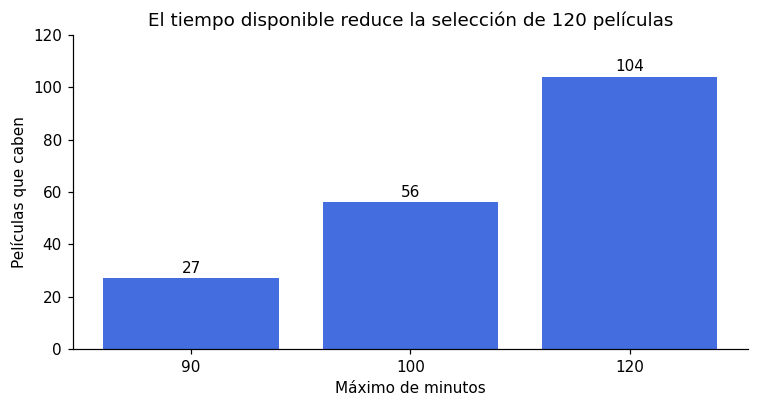

Sin el mediometraje: [26, 55, 103]


In [3]:
# cuento las opciones que caben en cada límite y comparo con la duración de wikidata
limites = [90, 100, 120]
tiempos = pd.DataFrame({'minutos': limites, 'peliculas': [int(peliculas.duracion.le(n).sum()) for n in limites]})
tiempos['con_wikidata'] = [int(pd.to_numeric(peliculas.duracion_max).le(n).sum()) for n in limites]
display(tiempos)
fig, eje = plt.subplots(figsize=(7, 3.8))
eje.bar(tiempos.minutos.astype(str), tiempos.peliculas, color=color_principal)
eje.set(title='El tiempo disponible reduce la selección de 120 películas', xlabel='Máximo de minutos', ylabel='Películas que caben')
eje.set_ylim(0, 120)
for i, n in enumerate(tiempos.peliculas):
    eje.text(i, n + 2, str(n), ha='center')
fig.tight_layout()
plt.show()
print('Sin el mediometraje:', [int(peliculas.loc[peliculas.titulo.ne('La cabina'), 'duracion'].le(n).sum()) for n in limites])

Compruebo que disponer de media hora más amplía mucho la oferta. No interpreto la duración como calidad o intensidad. La comparación con Wikidata muestra que una fuente distinta puede mover películas junto al límite: por eso documento la duración que utiliza el recomendador y pido comprobar la edición disponible.

## 4. Más antiguas no significa mejor valoradas
Comparo la mediana de las notas de las películas, no una media que dé más peso a los títulos con miles de votos. También comparo la mediana de votos. Una diferencia de pocas centésimas sobre cinco estrellas no permite proclamar una época ganadora.

,peliculas,nota_mediana,votos_mediana,duracion_mediana
epoca,,,,
Antes de 2000,70,3.608,6014.0,97.5
Desde 2000,50,3.624,2949.0,104.0


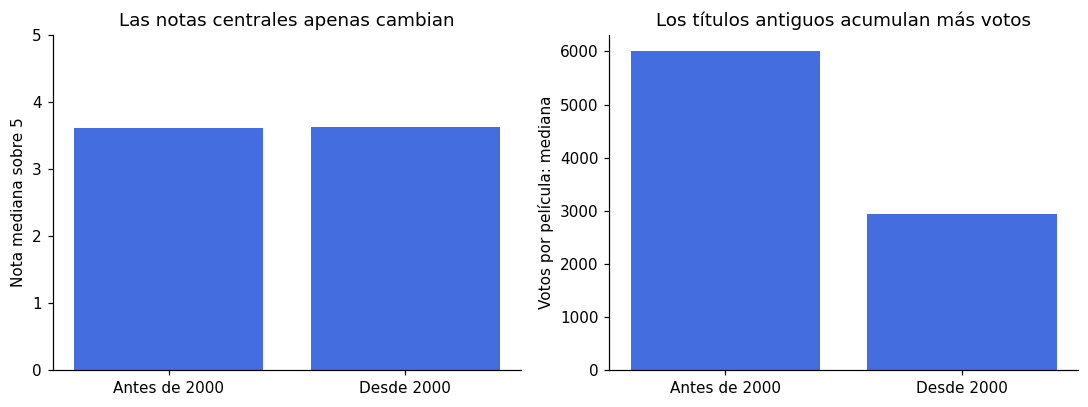

In [4]:
# comparo épocas dando el mismo peso a cada película
epocas = peliculas.groupby('epoca').agg(peliculas=('movie_id', 'size'), nota_mediana=('nota', 'median'), votos_mediana=('votos', 'median'), duracion_mediana=('duracion', 'median'))
display(epocas.round(3))
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8))
ejes[0].bar(epocas.index, epocas.nota_mediana, color=color_principal)
ejes[0].set(ylim=(0, 5), ylabel='Nota mediana sobre 5', title='Las notas centrales apenas cambian')
ejes[1].bar(epocas.index, epocas.votos_mediana, color=color_principal)
ejes[1].set(ylabel='Votos por película: mediana', title='Los títulos antiguos acumulan más votos')
fig.tight_layout()
plt.show()

Encuentro notas centrales próximas, pero distinto volumen de participación. No concluyo que los años causen los votos: influyen la selección editorial, la notoriedad y el tiempo transcurrido. Tampoco estos usuarios representan necesariamente al público español. El corte de 2023 deja menos recorrido a las incorporaciones recientes.

## 5. Familias, humor e intensidad: dimensiones distintas
No confundo una comedia con una película suave. Clasifico la intensidad en tres escalones editoriales: 1, atmósfera fantástica o amenaza sugerida con poca explicitud relativa; 2, amenaza sostenida o violencia puntual; 3, violencia explícita, daño corporal o angustia particularmente dura. Basta uno de esos rasgos para entrar en el tercero. No he hecho un experimento con espectadores ni una doble codificación independiente. Puedo discrepar de estas etiquetas; por eso las publico y no las convierto en una escala científica.

Las familias son múltiples y su recuento puede superar 120. La nota sigue siendo la valoración de los usuarios, nunca una estimación de cuánto miedo da la película.

In [5]:
# separo las etiquetas editoriales y mantengo visibles los tamaños de cada grupo
familias = peliculas.assign(familia=peliculas.familias.str.split('|')).explode('familia')
por_familia = familias.groupby('familia').agg(peliculas=('movie_id', 'size'), nota_mediana=('nota', 'median'), duracion_mediana=('duracion', 'median'))
display(por_familia.round(3))
display(pd.crosstab(peliculas.tono, peliculas.intensidad))
print('Coproducciones incluidas en España:', int(peliculas.paises.str.split('|').map(lambda ps: 'España' in ps).sum()))
print('Películas con menos de 500 votos:', int(peliculas.votos.lt(500).sum()))

,peliculas,nota_mediana,duracion_mediana
familia,,,
asesinos,15,3.523,95.0
ciencia-ficcion,18,3.597,100.0
fantasmas,20,3.611,104.5
monstruos,24,3.615,104.0
ocultismo,28,3.643,98.5
psicologico,25,3.654,104.0
vampiros,12,3.594,99.0
zombis,13,3.707,99.0


intensidad,1,2,3
tono,,,
humor,3,5,10
serio,8,35,59


Coproducciones incluidas en España: 12
Películas con menos de 500 votos: 10


Encuentro humor en distintos escalones de intensidad. Lo interpreto como una advertencia útil para elegir: los chistes no eliminan la violencia. Las diferencias entre familias describen esta selección y estas decisiones editoriales; no son una clasificación universal de subgéneros.

## 6. Comprobaciones de sensibilidad
Compruebo si la semejanza entre épocas depende de películas con pocos votos. Repito el cálculo exigiendo 500 y 1.000. También comparo distintas fronteras temporales. No busco una frontera que fabrique un titular. Reviso la relación entre duración y nota con la correlación de rangos: un valor próximo a cero describe poca asociación en el orden de las películas, sin demostrar causalidad.

In [6]:
# repito la comparación con distintos umbrales y fronteras para mostrar su dependencia
sensibilidad = []
for minimo in [0, 500, 1000]:
    for frontera in [1990, 2000, 2010]:
        grupo = peliculas[peliculas.votos.ge(minimo)]
        antes = grupo[grupo.anio.lt(frontera)]
        despues = grupo[grupo.anio.ge(frontera)]
        sensibilidad.append({'minimo_votos': minimo, 'frontera': frontera, 'n_antes': len(antes), 'n_despues': len(despues), 'mediana_antes': antes.nota.median(), 'mediana_despues': despues.nota.median()})
display(pd.DataFrame(sensibilidad).round(3))
correlacion = peliculas[['duracion', 'nota', 'anio', 'votos']].corr(method='spearman')
display(correlacion.round(3))

,minimo_votos,frontera,n_antes,n_despues,mediana_antes,mediana_despues
0,0,1990,51,69,3.678,3.588
1,0,2000,70,50,3.608,3.624
2,0,2010,88,32,3.620,3.615
3,500,1990,49,61,3.678,3.617
4,500,2000,67,43,3.617,3.649
5,500,2010,84,26,3.625,3.643
6,1000,1990,47,53,3.678,3.624
7,1000,2000,63,37,3.617,3.697
8,1000,2010,79,21,3.626,3.673


,duracion,nota,anio,votos
duracion,1.000,0.204,0.274,0.164
nota,0.204,1.000,-0.154,0.343
anio,0.274,-0.154,1.000,-0.245
votos,0.164,0.343,-0.245,1.000


No convierto estas asociaciones descriptivas en una predicción. La composición de la muestra y la frontera elegida afectan a las comparaciones. No trato los votos como observaciones independientes para calcular un intervalo poblacional: los mismos usuarios pueden puntuar varias películas y he conservado agregados, no un diseño de encuesta representativa.

## 7. Reglas transparentes del recomendador
Filtro simultáneamente por familia, época, tiempo, tono, procedencia e intensidad máxima. No relajo filtros a escondidas si no hay resultados. Ordeno las coincidencias por media de estrellas sin redondear; en empates, por número de votos y después por identificador. Permito cambiar el orden al número de votos para comparar. Muestro tres resultados y dejo acceder al resto.

No utilizo aprendizaje automático ni una puntuación secreta de afinidad. La explicación de cada resultado enumera los filtros satisfechos y muestra sus fuentes. Marco los títulos con menos de 500 votos como una referencia con menos participación, sin eliminarlos automáticamente.

In [7]:
# compruebo ejemplos concretos y exporto los mismos datos que consume la interacción
ordenadas = peliculas.sort_values(['nota', 'votos', 'movie_id'], ascending=[False, False, True])
ejemplos = {
    'Sin restricciones': ordenadas,
    'Humor y hasta 90 minutos': ordenadas[ordenadas.tono.eq('humor') & ordenadas.duracion.le(90)],
    'Fantasmas desde 2000': ordenadas[ordenadas.familias.str.split('|').map(lambda x: 'fantasmas' in x) & ordenadas.anio.ge(2000)],
    'España y hasta 90 minutos': ordenadas[ordenadas.paises.str.split('|').map(lambda x: 'España' in x) & ordenadas.duracion.le(90)]
}
for nombre, ejemplo in ejemplos.items():
    print(nombre, ':', len(ejemplo), 'coincidencias')
    display(ejemplo[['titulo', 'anio', 'duracion', 'nota', 'votos']].head(3).round(3))
columnas_web = ['movie_id','titulo','anio','duracion','duraciones_ficha','nota','votos','familias','intensidad','tono','sinopsis','paises','fuente_sinopsis','fuente_duracion','wikidata','criterio_intensidad','nota_anio']
registros = json.loads(peliculas[columnas_web].to_json(orient='records', force_ascii=False))
(base / 'peliculas.json').write_text(json.dumps(registros, ensure_ascii=False, indent=2), encoding='utf-8')
resultados = {'peliculas': len(peliculas), 'votos': int(peliculas.votos.sum()), 'tiempos': tiempos.to_dict('records'), 'epocas': epocas.reset_index().to_dict('records'), 'sensibilidad': sensibilidad, 'humor': int(peliculas.tono.eq('humor').sum()), 'humor_intenso': int((peliculas.tono.eq('humor') & peliculas.intensidad.eq(3)).sum()), 'menos_500': int(peliculas.votos.lt(500).sum())}
(base / 'resultados.json').write_text(json.dumps(resultados, ensure_ascii=False, indent=2), encoding='utf-8')
peliculas.to_csv(base / 'peliculas_analizadas.csv', index=False)
print('Exporto datos y resultados calculados, sin predicciones.')

Sin restricciones : 120 coincidencias


,titulo,anio,duracion,nota,votos
36,El silencio de los corderos,1991,118,4.148,90330
24,"Alien, el octavo pasajero",1979,116,4.068,45211
10,Psicosis,1960,109,4.063,27027


Humor y hasta 90 minutos : 6 coincidencias


,titulo,anio,duracion,nota,votos
107,Lo que hacemos en las sombras,2014,85,4.010,4918
106,Tucker y Dale contra el mal,2010,89,3.833,5032
111,Terroríficamente muertos,1987,84,3.792,9858


Fantasmas desde 2000 : 11 coincidencias


,titulo,anio,duracion,nota,votos
43,El orfanato,2007,97,3.724,2904
42,El espinazo del diablo,2001,108,3.720,2032
41,Los otros,2001,104,3.710,16578


España y hasta 90 minutos : 2 coincidencias


,titulo,anio,duracion,nota,votos
44,[REC],2007,78,3.707,2994
51,La cabina,1972,35,3.599,71


Exporto datos y resultados calculados, sin predicciones.


## 8. Conclusión y límites
Respondo a mi pregunta con una elección condicionada: la película mejor puntuada no es siempre la que cabe en la noche del lector. Encuentro notas centrales parecidas entre las dos épocas principales, una participación desigual y una oferta que cambia mucho con el tiempo disponible.

Mantengo cinco límites: selección editorial; votos históricos hasta 2023; sesgo de los usuarios de MovieLens; metadatos y montajes que pueden discrepar; etiquetas de intensidad subjetivas sin validación con espectadores. No compruebo disponibilidad en plataformas ni clasifico películas para menores. No generalizo el análisis a todo el cine de terror.

Para reproducir este cuaderno, instalo `requirements.txt` y lo ejecuto desde su carpeta, con los CSV, `huellas.json` y la licencia a su lado. No necesito una clave de API ni volver a descargar los 32 millones de votos. Para auditar la extracción original, conservo el ZIP verificado de MovieLens y los scripts en la carpeta local del análisis.